# 2323 CIS — Introduction to Data Science
## Lab 14 | Lab Project Development and GitHub Publishing

| | |
|---|---|
| **Name** | Ammar Alessi |
| **Student ID** | 446802581 |
| **Course** | 2323 CIS — King Khalid University |
| **Lab** | 14 (2 hours) |
| **CLO(s)** | 2.1 – 2.5, 3.1 |
| **Environment** | Google Colab / Jupyter (Python, NumPy, pandas, Matplotlib) |

# KKU Student IT Help-Desk Tickets: Demand, Response Time and SLA Performance
**Course project — 2323 CIS Introduction to Data Science** (individual submission)

## 1. Project question and objective
**Question:** *Which departments and issue categories generate the most help-desk tickets, how does weekly demand change over the semester, and are tickets resolved within their service-level (SLA) targets?*

**Practical objective:** give the IT support team evidence about where demand is concentrated, when it peaks, and which priority levels miss their SLA, so staffing can be planned.

**Author:** Ammar Alessi (446802581) — individual project. See the *Contribution statement* at the end of this notebook and in `README.md`.

## 2. Data sources and documentation
| Source | Format | Content | How it is used |
|---|---|---|---|
| `data/raw/helpdesk_tickets_raw.csv` | CSV (messy) | One row per ticket: raw date text, requester e-mail, department code, category, priority, resolution hours, free-text notes | Main dataset: needs loading **and** cleaning |
| `data/raw/departments.json` | JSON | Department code, name, college, staff count | Merged to add department information |
| `data/raw/sla_targets.xlsx` | Excel | Hours allowed to resolve a ticket per priority | Merged to evaluate SLA compliance |

> **Important data note:** these three files are **simulated** (generated with a fixed random seed by the cell below) to mimic a real help-desk export, because no real ticket log is available to the author. Nothing in them is real personal data. The pipeline (load → understand → clean → transform → analyse → visualize) is written so that it can be re-used on a real export with the same columns.
>
> **Source / access date:** generated in code, 2026-11-08. Time unit: **one ticket per row; dates are daily**; the analysis period is 2026-01-01 to 2026-06-30.

## 3. Setup and data acquisition (reproducible)

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 50)

# Works both inside the GitHub repo (notebook in /notebooks) and standalone in Colab (current folder)
ROOT = Path('..') if Path('../data').exists() else Path('.')
RAW, PROC, FIG = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed', ROOT / 'outputs' / 'figures'
for p in (RAW, PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT.resolve())

Project root: /home/claude/repo/kku-helpdesk-analysis


In [2]:
def generate_raw_data(raw_dir, seed=2323, n=620):
    """Create the three simulated raw files (only used when they do not exist yet)."""
    rng = np.random.default_rng(seed)
    depts = pd.DataFrame({
        'dept_code': ['CS', 'IS', 'EE', 'BA', 'MD', 'LW', 'AR', 'SC'],
        'dept_name': ['Computer Science', 'Information Systems', 'Electrical Engineering', 'Business Administration',
                      'Medicine', 'Law', 'Arts', 'Science'],
        'college': ['Computer Science', 'Computer Science', 'Engineering', 'Business', 'Medicine', 'Law', 'Arts', 'Science'],
        'staff_count': [60, 45, 70, 55, 90, 30, 40, 65],
    })
    depts.to_json(raw_dir / 'departments.json', orient='records', indent=2)
    pd.DataFrame({'priority': ['High', 'Medium', 'Low'], 'sla_hours': [8, 24, 72]}).to_excel(raw_dir / 'sla_targets.xlsx', index=False)

    start = pd.Timestamp('2026-01-01')
    days = (pd.Timestamp('2026-06-30') - start).days + 1
    weights = np.linspace(0.7, 1.4, days)                         # demand grows during the semester
    dates_all = start + pd.to_timedelta(np.arange(days), unit='D')
    weights = weights * np.where(dates_all.dayofweek.isin([4, 5]), 0.25, 1.0)    # Fri/Sat are weekend days in Saudi Arabia
    weights = weights * np.where(((dates_all >= '2026-04-20') & (dates_all <= '2026-05-05')), 2.0, 1.0)  # exam-period peak
    weights = weights / weights.sum()
    dates = dates_all[rng.choice(days, size=n, p=weights)].sort_values()

    d_codes = rng.choice(depts['dept_code'], size=n, p=[.22, .18, .14, .12, .12, .06, .08, .08])
    cats = rng.choice(['wifi', 'email', 'lms', 'printing', 'software', 'account'], size=n, p=[.28, .16, .2, .1, .14, .12])
    prio = rng.choice(['High', 'Medium', 'Low'], size=n, p=[.2, .5, .3])
    base = {'High': 6, 'Medium': 20, 'Low': 55}
    hours = np.array([max(0.5, rng.lognormal(np.log(base[p]), 0.55)) for p in prio]).round(1)

    # --- make it messy on purpose ---
    def fmt_date(d, k):
        return [d.strftime('%Y-%m-%d'), d.strftime('%d/%m/%Y'), d.strftime('%b %d, %Y')][k]
    date_txt = [fmt_date(d, k) for d, k in zip(dates, rng.integers(0, 3, n))]
    cat_variants = {'wifi': ['wifi', 'WiFi', 'Wi-Fi', ' wifi '], 'email': ['email', 'Email', 'E-mail'],
                    'lms': ['lms', 'LMS', 'Lms'], 'printing': ['printing', 'Printing'],
                    'software': ['software', 'Software', 'SOFTWARE'], 'account': ['account', 'Account', 'ACCOUNT ']}
    cat_txt = [rng.choice(cat_variants[c]) for c in cats]
    prio_variants = {'High': ['High', 'high', 'HIGH'], 'Medium': ['Medium', 'medium', 'MED', 'Med'], 'Low': ['Low', 'low', 'LOW']}
    prio_txt = [rng.choice(prio_variants[p]) for p in prio]
    dept_txt = [rng.choice([c, c.lower(), ' ' + c + ' ']) if rng.random() < .25 else c for c in d_codes]
    first = ['sara', 'omar', 'huda', 'fahad', 'noor', 'khalid', 'reem', 'saad', 'lama', 'ali']
    emails = [f"{rng.choice(first)}{rng.integers(10, 99)}@kku.edu.sa" for _ in range(n)]
    for i in rng.choice(n, 12, replace=False):                     # a few malformed e-mails
        emails[i] = emails[i].replace('@', '.at.') if i % 2 else emails[i].replace('.edu.sa', '')
    emails = [e.upper() if rng.random() < .1 else e for e in emails]
    hours_txt = [str(h) for h in hours]
    for i in rng.choice(n, 25, replace=False):
        hours_txt[i] = rng.choice(['n/a', 'unknown', ''])           # missing resolution time
    notes = []
    for i in range(n):
        parts = [rng.choice(['Student cannot connect', 'Password reset needed', 'Page not loading', 'Printer jammed',
                             'Licence expired', 'Mailbox full', 'Slow connection'])]
        if rng.random() < .45:
            parts.append(f"call back 05{rng.integers(10000000, 99999999)}")
        if rng.random() < .5:
            parts.append(f"room {rng.choice(list('ABCD'))}-{rng.integers(100, 499)}")
        notes.append('; '.join(parts))
    df = pd.DataFrame({'ticket': [f'T-{1000 + i}' for i in range(n)], 'opened_raw': date_txt, 'requester': emails,
                       'dept_code': dept_txt, 'category': cat_txt, 'priority': prio_txt,
                       'resolution_hours': hours_txt, 'notes': notes})
    for i in rng.choice(n, 20, replace=False):
        df.loc[i, 'priority'] = None                                # missing priority
    df = pd.concat([df, df.sample(25, random_state=1)], ignore_index=True).sample(frac=1, random_state=3)
    df = df.sort_values('ticket', kind='stable').reset_index(drop=True)   # duplicates stay next to each other
    df.to_csv(raw_dir / 'helpdesk_tickets_raw.csv', index=False)


if not (RAW / 'helpdesk_tickets_raw.csv').exists():
    generate_raw_data(RAW)
    print('Simulated raw data created in', RAW)
else:
    print('Raw data already present in', RAW)

Raw data already present in ../data/raw


## 4. Data understanding

In [3]:
tickets_raw = pd.read_csv(RAW / 'helpdesk_tickets_raw.csv')
departments = pd.read_json(RAW / 'departments.json')
sla = pd.read_excel(RAW / 'sla_targets.xlsx')

print('Tickets  :', tickets_raw.shape, '| Departments:', departments.shape, '| SLA targets:', sla.shape)
display(tickets_raw.head(8))

Tickets  : (645, 8) | Departments: (8, 4) | SLA targets: (3, 2)


,ticket,opened_raw,requester,dept_code,category,priority,resolution_hours,notes
0,T-1000,01/01/2026,reem94@kku.edu.sa,SC,SOFTWARE,medium,36.6,Slow connection; call back 0587037391; room C-180
1,T-1001,2026-01-01,reem16@kku.edu.sa,EE,LMS,High,5.6,Page not loading; call back 0546478854; room C...
2,T-1002,2026-01-01,khalid82@kku.edu.sa,CS,wifi,medium,25.3,Printer jammed; room A-214
3,T-1003,"Jan 01, 2026",omar84@kku.edu.sa,MD,software,LOW,79.5,Slow connection; room B-350
4,T-1004,2026-01-03,noor46@kku.edu.sa,CS,Account,MED,17.2,Student cannot connect
5,T-1005,2026-01-04,lama12@kku.edu.sa,CS,SOFTWARE,Medium,20.7,Licence expired; call back 0564723098; room D-299
6,T-1006,"Jan 04, 2026",huda29@kku.edu.sa,CS,Account,Med,20.4,Page not loading; room B-205
7,T-1007,2026-01-04,noor39@kku.edu.sa,CS,account,high,2.6,Student cannot connect; call back 0566542070; ...


In [4]:
print('Data types:'); print(tickets_raw.dtypes.to_string())
print('\nMissing values per column:'); print(tickets_raw.isna().sum().to_string())
print('\nExact duplicate rows:', tickets_raw.duplicated().sum())
print('\nDistinct category labels (raw):', tickets_raw['category'].nunique(), '->', sorted(tickets_raw['category'].unique()))
print('Distinct priority labels (raw):', sorted(tickets_raw['priority'].dropna().unique()))
print('Distinct dept_code labels (raw):', tickets_raw['dept_code'].nunique())
print('\nSample of date formats:', tickets_raw['opened_raw'].sample(5, random_state=0).tolist())
print('Non-numeric resolution_hours values:', sorted(set(tickets_raw['resolution_hours'].dropna()[pd.to_numeric(tickets_raw['resolution_hours'], errors='coerce').isna()].astype(str))))

Data types:
ticket              str
opened_raw          str
requester           str
dept_code           str
category            str
priority            str
resolution_hours    str
notes               str

Missing values per column:
ticket               0
opened_raw           0
requester            0
dept_code            0
category             0
priority            22
resolution_hours    18
notes                0

Exact duplicate rows: 25

Distinct category labels (raw): 18 -> [' wifi ', 'ACCOUNT ', 'Account', 'E-mail', 'Email', 'LMS', 'Lms', 'Printing', 'SOFTWARE', 'Software', 'Wi-Fi', 'WiFi', 'account', 'email', 'lms', 'printing', 'software', 'wifi']
Distinct priority labels (raw): ['HIGH', 'High', 'LOW', 'Low', 'MED', 'Med', 'Medium', 'high', 'low', 'medium']
Distinct dept_code labels (raw): 24

Sample of date formats: ['23/04/2026', '2026-06-02', '2026-04-20', '02/04/2026', 'Apr 06, 2026']
Non-numeric resolution_hours values: ['unknown']


**Data-quality issues found (before cleaning):**
1. Exact duplicate rows (the same ticket exported twice).
2. Dates written in three different text formats.
3. Category, priority and department codes with inconsistent spelling, case and spaces.
4. `resolution_hours` stored as text with values such as `n/a` / `unknown` / empty.
5. Missing priorities.
6. Some requester e-mails are malformed or upper-case.
7. Phone numbers and room codes are buried inside free-text notes (they need regular expressions).

## 5. Data preparation
### 5.1 Cleaning (duplicates, labels, types, missing values)

In [5]:
t = tickets_raw.drop_duplicates().copy()
print('Rows before:', len(tickets_raw), '| after removing duplicates:', len(t))

# standardize text labels
t['dept_code'] = t['dept_code'].str.strip().str.upper()
t['category'] = (t['category'].str.lower().str.replace(r'[^a-z]', '', regex=True))   # 'Wi-Fi', ' wifi ' -> 'wifi'
t['category'] = t['category'].replace({'wifi': 'WiFi', 'email': 'Email', 'lms': 'LMS', 'printing': 'Printing',
                                       'software': 'Software', 'account': 'Account'})
t['priority'] = (t['priority'].str.strip().str.title().replace({'Med': 'Medium'})).fillna('Medium')
t['requester'] = t['requester'].str.strip().str.lower()

# numeric conversion
t['resolution_hours'] = pd.to_numeric(t['resolution_hours'], errors='coerce')
t['resolution_missing'] = t['resolution_hours'].isna()
print('Tickets with unknown resolution time:', int(t['resolution_missing'].sum()))
print('Categories now:', sorted(t['category'].unique()), '| priorities:', sorted(t['priority'].unique()))

Rows before: 645 | after removing duplicates: 620
Tickets with unknown resolution time: 25
Categories now: ['Account', 'Email', 'LMS', 'Printing', 'Software', 'WiFi'] | priorities: ['High', 'Low', 'Medium']


**Decisions (quality log):**
- Duplicates removed; labels standardized with `strip`, `lower`, regex and `replace`.
- **Missing priority** (a few dozen rows) is set to `Medium` (the most common level) — a documented assumption that slightly biases results toward Medium.
- **Missing resolution time** is *not* guessed: it is flagged (`resolution_missing`) and excluded from time statistics, because inventing resolution times would change the SLA conclusion.

In [6]:
# dates: three formats, parsed explicitly with the matching format (avoids day/month confusion)
d = t['opened_raw'].str.strip()
is_iso = d.str.fullmatch(r'\d{4}-\d{2}-\d{2}')
is_slash = d.str.fullmatch(r'\d{2}/\d{2}/\d{4}')
opened = pd.Series(pd.NaT, index=t.index, dtype='datetime64[ns]')
opened[is_iso] = pd.to_datetime(d[is_iso], format='%Y-%m-%d')
opened[is_slash] = pd.to_datetime(d[is_slash], format='%d/%m/%Y')        # assumption: day/month/year
opened[~is_iso & ~is_slash] = pd.to_datetime(d[~is_iso & ~is_slash], format='%b %d, %Y')
t['opened'] = opened
print('Unparsed dates:', t['opened'].isna().sum(), '| range:', t['opened'].min().date(), '->', t['opened'].max().date())

Unparsed dates: 0 | range: 2026-01-01 -> 2026-06-30


### 5.2 Regular-expression extraction from text

In [7]:
# phone number (05 + 8 digits) and room code (A-D, dash, 3 digits) hidden in the free-text notes
t['phone'] = t['notes'].str.extract(r'\b(05\d{8})\b', expand=False)
t['room'] = t['notes'].str.extract(r'\b([A-D]-\d{3})\b', expand=False)
t['building'] = t['room'].str.extract(r'^([A-D])', expand=False)
t['ticket_no'] = t['ticket'].str.extract(r'T-(\d+)', expand=False).astype(int)

# e-mail validation and domain
t['email_valid'] = t['requester'].str.fullmatch(r'[\w.-]+@kku\.edu\.sa')
t['email_domain'] = t['requester'].str.extract(r'@([\w.-]+)$', expand=False)
print('Phone found in', t['phone'].notna().sum(), 'tickets | room found in', t['room'].notna().sum(), 'tickets')
print('Invalid e-mails:', (~t['email_valid']).sum())
display(t[['ticket', 'notes', 'phone', 'room', 'building']].head(6))

Phone found in 297 tickets | room found in 315 tickets
Invalid e-mails: 12


,ticket,notes,phone,room,building
0,T-1000,Slow connection; call back 0587037391; room C-180,0587037391,C-180,C
1,T-1001,Page not loading; call back 0546478854; room C...,0546478854,C-309,C
2,T-1002,Printer jammed; room A-214,NaN,A-214,A
3,T-1003,Slow connection; room B-350,NaN,B-350,B
4,T-1004,Student cannot connect,NaN,NaN,NaN
5,T-1005,Licence expired; call back 0564723098; room D-299,0564723098,D-299,D


### 5.3 Merge, transformation and analysis-ready table

In [8]:
# merge with departments (many tickets -> one department) and SLA targets (many tickets -> one priority)
m = t.merge(departments, on='dept_code', how='left', validate='many_to_one', indicator='dept_match')
print('Department merge result:'); print(m['dept_match'].value_counts().to_string())
m = m.drop(columns='dept_match').merge(sla, on='priority', how='left', validate='many_to_one')

# transformations
m['met_sla'] = np.where(m['resolution_missing'], np.nan, (m['resolution_hours'] <= m['sla_hours']).astype(float))
m['hours_vs_sla'] = m['resolution_hours'] / m['sla_hours']          # >1 means the SLA was exceeded
m['resolution_band'] = pd.cut(m['resolution_hours'], bins=[0, 4, 12, 24, 72, np.inf],
                              labels=['<=4h', '4-12h', '12-24h', '1-3 days', '>3 days'])
m['weekday'] = m['opened'].dt.day_name()
m['month'] = m['opened'].dt.to_period('M').astype(str)

final = m.sort_values('opened').reset_index(drop=True)
final.to_csv(PROC / 'helpdesk_clean.csv', index=False)
print('Analysis-ready dataset:', final.shape, '-> saved to', PROC / 'helpdesk_clean.csv')
display(final[['ticket', 'opened', 'dept_name', 'category', 'priority', 'resolution_hours', 'sla_hours', 'met_sla']].head())

Department merge result:
dept_match
both          620
left_only       0
right_only      0
Analysis-ready dataset: (620, 25) -> saved to ../data/processed/helpdesk_clean.csv


,ticket,opened,dept_name,category,priority,resolution_hours,sla_hours,met_sla
0,T-1000,2026-01-01,Science,Software,Medium,36.6,24,0.0
1,T-1001,2026-01-01,Electrical Engineering,LMS,High,5.6,8,1.0
2,T-1002,2026-01-01,Computer Science,WiFi,Medium,25.3,24,0.0
3,T-1003,2026-01-01,Medicine,Software,Low,79.5,72,0.0
4,T-1004,2026-01-03,Computer Science,Account,Medium,17.2,24,1.0


### 5.4 Before / after quality check

In [9]:
check = pd.DataFrame({
    'Before (raw)': [len(tickets_raw), tickets_raw.duplicated().sum(), tickets_raw['category'].nunique(),
                     tickets_raw['priority'].nunique(dropna=True), tickets_raw['priority'].isna().sum(),
                     int(pd.to_numeric(tickets_raw['resolution_hours'], errors='coerce').isna().sum())],
    'After (clean)': [len(final), final.duplicated().sum(), final['category'].nunique(),
                      final['priority'].nunique(), final['priority'].isna().sum(), int(final['resolution_missing'].sum())],
}, index=['Rows', 'Duplicate rows', 'Distinct categories', 'Distinct priority labels', 'Missing priority', 'Unknown resolution time'])
display(check)

,Before (raw),After (clean)
Rows,645,620
Duplicate rows,25,0
Distinct categories,18,6
Distinct priority labels,10,3
Missing priority,22,0
Unknown resolution time,25,25


## 6. Analysis: aggregation and pivoting

In [10]:
by_cat = final.groupby('category').agg(tickets=('ticket', 'count'), median_hours=('resolution_hours', 'median')).sort_values('tickets', ascending=False)
display(by_cat)

pivot = pd.pivot_table(final, index='dept_name', columns='category', values='ticket', aggfunc='count', fill_value=0, margins=True)
display(pivot)

by_dept = final.groupby('dept_name').agg(tickets=('ticket', 'count'), staff=('staff_count', 'first'))
by_dept['tickets_per_10_staff'] = (by_dept['tickets'] / by_dept['staff'] * 10).round(2)
display(by_dept.sort_values('tickets_per_10_staff', ascending=False))

sla_tab = final.groupby('priority').agg(tickets=('ticket', 'count'), median_hours=('resolution_hours', 'median'),
                                        sla_hours=('sla_hours', 'first'), sla_met_pct=('met_sla', lambda s: round(s.mean() * 100, 1)))
display(sla_tab.loc[['High', 'Medium', 'Low']])

,tickets,median_hours
category,,
WiFi,167,20.0
LMS,130,24.2
Email,101,21.8
Software,96,23.5
Account,78,20.3
Printing,48,24.1


category,Account,Email,LMS,Printing,Software,WiFi,All
dept_name,,,,,,,
Arts,8,9,10,4,9,10,50
Business Administration,9,11,11,8,9,26,74
Computer Science,21,24,30,14,25,36,150
Electrical Engineering,6,11,18,6,9,22,72
Information Systems,11,17,26,4,12,32,102
Law,6,8,6,2,7,10,39
Medicine,7,14,19,6,15,24,85
Science,10,7,10,4,10,7,48
All,78,101,130,48,96,167,620


,tickets,staff,tickets_per_10_staff
dept_name,,,
Computer Science,150,60,25.00
Information Systems,102,45,22.67
Business Administration,74,55,13.45
Law,39,30,13.00
Arts,50,40,12.50
Electrical Engineering,72,70,10.29
Medicine,85,90,9.44
Science,48,65,7.38


,tickets,median_hours,sla_hours,sla_met_pct
priority,,,,
High,99,5.7,8,68.0
Medium,325,18.6,24,67.8
Low,196,55.2,72,71.1


## 7. Analysis: time series

In [11]:
ts = final.set_index('opened').sort_index()
daily = ts['ticket'].resample('D').count()
weekly = ts['ticket'].resample('W').count()
roll4 = weekly.rolling(4).mean()
print('Busiest week ending', weekly.idxmax().date(), 'with', weekly.max(), 'tickets | quietest week:', weekly.idxmin().date(), 'with', weekly.min())
print('Tickets by weekday:'); print(final['weekday'].value_counts().reindex(['Sunday','Monday','Tuesday','Wednesday','Thursday','Friday','Saturday']).to_string())
print('Tickets per month:'); print(final['month'].value_counts().sort_index().to_string())

Busiest week ending 2026-04-26 with 54 tickets | quietest week: 2026-01-04 with 9
Tickets by weekday:
weekday
Sunday       112
Monday       115
Tuesday      112
Wednesday     92
Thursday     128
Friday        22
Saturday      39
Tickets per month:
month
2026-01     68
2026-02     60
2026-03    101
2026-04    154
2026-05    114
2026-06    123


## 8. Visualizations and interpretation

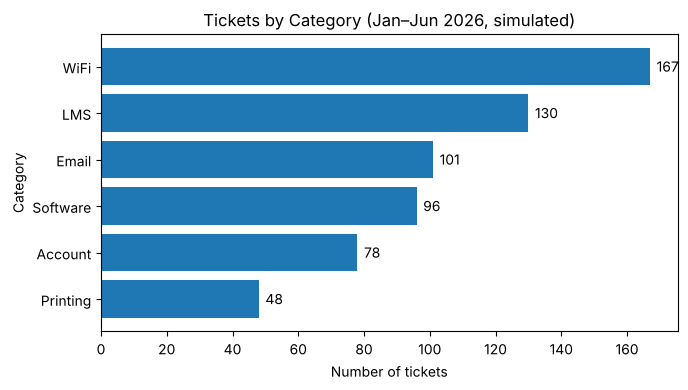

category
WiFi        26.9%
LMS         21.0%
Email       16.3%
Software    15.5%
Account     12.6%
Printing     7.7%


In [12]:
cat_counts = by_cat['tickets'].sort_values()
plt.figure(figsize=(7, 4))
plt.barh(cat_counts.index, cat_counts.values, color='tab:blue')
for i, v in enumerate(cat_counts.values):
    plt.text(v + 2, i, str(v), va='center')
plt.title('Tickets by Category (Jan–Jun 2026, simulated)'); plt.xlabel('Number of tickets'); plt.ylabel('Category')
plt.tight_layout(); plt.savefig(FIG / 'fig1_tickets_by_category.png', dpi=150); plt.show()
print(by_cat['tickets'].div(len(final)).mul(100).round(1).astype(str).add('%').to_string())

**Figure 1 interpretation:** WiFi is the largest category (26.9% of tickets), followed by LMS (21.0%) and Email (16.3%); WiFi and LMS alone account for about 48% of all tickets, while printing is the smallest category (7.7%). This is an observation about volume only — it does not say which problems are hardest to fix.

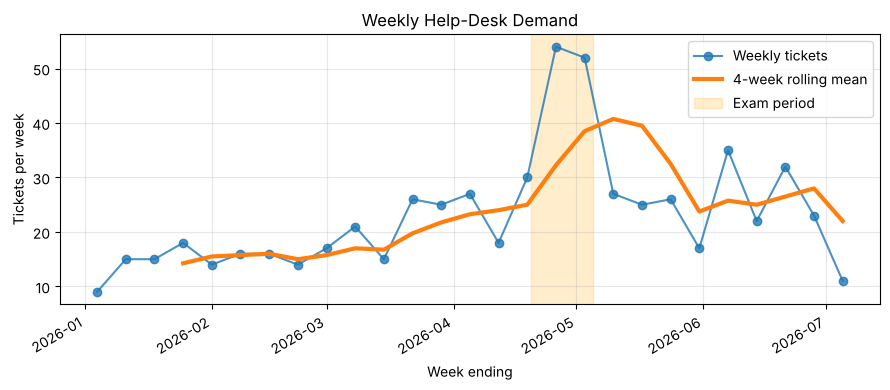

In [13]:
plt.figure(figsize=(9, 4))
plt.plot(weekly.index, weekly.values, marker='o', label='Weekly tickets', alpha=0.8)
plt.plot(roll4.index, roll4.values, linewidth=3, label='4-week rolling mean')
plt.axvspan(pd.Timestamp('2026-04-20'), pd.Timestamp('2026-05-05'), color='orange', alpha=0.2, label='Exam period')
plt.title('Weekly Help-Desk Demand'); plt.xlabel('Week ending'); plt.ylabel('Tickets per week'); plt.legend(); plt.grid(alpha=0.3)
plt.gcf().autofmt_xdate(); plt.tight_layout(); plt.savefig(FIG / 'fig2_weekly_demand.png', dpi=150); plt.show()

**Figure 2 interpretation:** demand starts low in January (9 tickets in the first partial week), rises through the semester and peaks in the exam period (shaded; busiest week ending 2026-04-26 with 54 tickets). After the exams demand drops back but stays well above the early-semester level (monthly totals: 68 in January, 154 in April, 123 in June). The support team should therefore plan extra capacity for the weeks around exams.

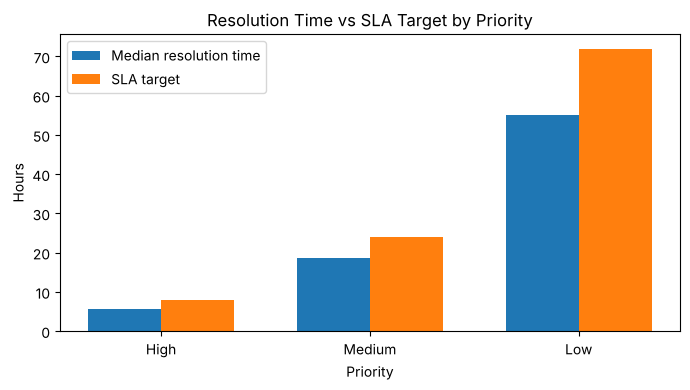

          median_hours  sla_hours  sla_met_pct
priority                                      
High               5.7          8         68.0
Medium            18.6         24         67.8
Low               55.2         72         71.1


In [14]:
order = ['High', 'Medium', 'Low']
res = sla_tab.loc[order]
x = np.arange(3); w = 0.35
plt.figure(figsize=(7, 4))
plt.bar(x - w/2, res['median_hours'], w, label='Median resolution time')
plt.bar(x + w/2, res['sla_hours'], w, label='SLA target', color='tab:orange')
plt.xticks(x, order); plt.xlabel('Priority'); plt.ylabel('Hours'); plt.title('Resolution Time vs SLA Target by Priority')
plt.legend(); plt.tight_layout(); plt.savefig(FIG / 'fig3_resolution_vs_sla.png', dpi=150); plt.show()
print(res[['median_hours', 'sla_hours', 'sla_met_pct']].to_string())

**Figure 3 interpretation:** the typical (median) ticket is resolved inside its SLA for every priority (5.7 h vs 8 h for High, 18.6 h vs 24 h for Medium, 55.2 h vs 72 h for Low), but only about 68–71% of tickets actually meet the target (68.0% High, 67.8% Medium, 71.1% Low). So roughly one ticket in three misses its SLA at every priority level; the median alone would hide this, which is why the compliance percentage is reported as well.

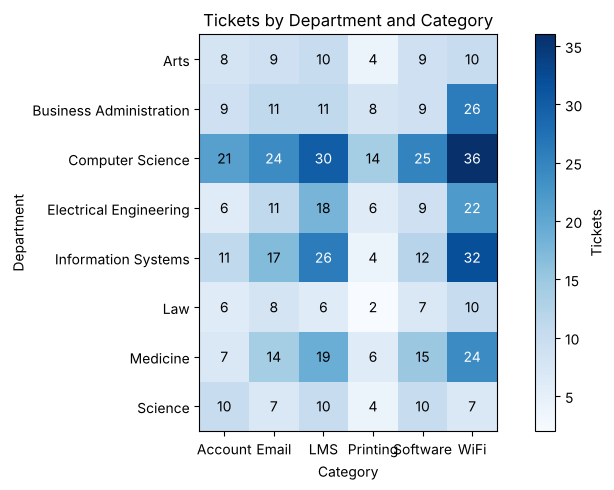

In [15]:
mat = pivot.drop(index='All', columns='All')
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(mat.values, cmap='Blues')
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, mat.values[i, j], ha='center', va='center', color='black' if mat.values[i, j] < mat.values.max() * 0.6 else 'white')
ax.set_title('Tickets by Department and Category'); ax.set_xlabel('Category'); ax.set_ylabel('Department')
fig.colorbar(im, label='Tickets'); plt.tight_layout(); plt.savefig(FIG / 'fig4_dept_category_heatmap.png', dpi=150); plt.show()

**Figure 4 interpretation:** the darkest cells show where demand concentrates: Computer Science (150 tickets) and Information Systems (102), mainly for WiFi and LMS. Because departments differ in size, the *tickets per 10 staff* table is a fairer comparison: Computer Science (25.0) and Information Systems (22.7) are highest, while Science (7.4) and Medicine (9.4) are lowest.

## 9. Conclusions and limitations
**Conclusions**
- Demand is concentrated in a few categories (WiFi, LMS, Email), so improving those services would reduce the most tickets.
- Weekly demand grows during the semester and peaks in the exam period.
- Typical (median) resolution times are within SLA, but only about 68–71% of tickets meet the target at each priority level, so about one in three misses it.

**Limitations**
- The data is **simulated**, so these findings demonstrate the *method*, not real KKU performance.
- Missing priorities were set to Medium and tickets with unknown resolution time were excluded from time statistics; both choices affect the SLA percentages.
- Slash-formatted dates were assumed to be day/month/year.
- Weeks end on Sunday, so the first week (1–4 January) and the last week (29–30 June) are partial and look artificially low.
- No statistical testing was done; the charts describe, they do not prove causes.

## 10. Reproducibility check
1. *Runtime → Restart session*, then *Run all* — the notebook runs from top to bottom with no errors.
2. If the raw files are missing, the notebook regenerates the same simulated files (fixed seed `2323`).
3. Outputs: `data/processed/helpdesk_clean.csv` and four figures in `outputs/figures/`.

In [16]:
print('Final dataset exists :', (PROC / 'helpdesk_clean.csv').exists())
print('Figures saved         :', sorted(p.name for p in FIG.glob('*.png')))
print('Rows x columns (final):', final.shape)
print('Missing values in key analysis columns:', int(final[['opened', 'dept_name', 'category', 'priority']].isna().sum().sum()))

Final dataset exists : True
Figures saved         : ['fig1_tickets_by_category.png', 'fig2_weekly_demand.png', 'fig3_resolution_vs_sla.png', 'fig4_dept_category_heatmap.png']
Rows x columns (final): (620, 25)
Missing values in key analysis columns: 0


## 11. Contribution statement
| Author | Student ID | Contribution |
|---|---|---|
| Ammar Alessi | 446802581 | Individual project: all work — question and data design, cleaning and regex extraction, merge/aggregation, time-series analysis, visualizations and interpretation, README, GitHub repository and presentation |

*This project was completed individually. If the instructor later assigns groups, add the other members to this table.*